# **Exercise 11: Building a BERTopic Pipeline from Scratch**

## **Introduction**
BERTopic is a powerful topic modeling technique that uses transformer-based embeddings, dimensionality reduction, and clustering to extract meaningful topics from textual data. In this exercise, we will manually construct a BERTopic pipeline.
We will use the "20 Newsgroups dataset", which is a popular collection of approximately 20,000 newsgroup documents, organized into 20 different categories such as sports, politics, and technology.

## **Pipeline Overview**
We will break down the BERTopic process into four key stages:

1. **Embedding Phase**  
   - We will use a **Sentence Transformer** to convert text into numerical representations (embeddings).  
   - Sentence transformers provide high-quality embeddings suitable for clustering.

2. **Dimensionality Reduction**  
   - High-dimensional embeddings are difficult to cluster effectively, so we will first reduce their dimensionality.  
   - We will compare two dimensionality reduction methods: **PCA (Principal Component Analysis)** and **UMAP (Uniform Manifold Approximation and Projection)**.

3. **Clustering**  
   - We will use clustering algorithms to group similar documents together.  
   - Two clustering methods will be explored: **KMeans** and **HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise)**.

4. **Topic Interpretation**  
   - After clustering, we need to extract meaningful words that best represent each topic.  
   - We will use **Class-based TF-IDF** to determine the most representative words for each topic.

## **Learning Objectives**
By the end of this exercise, you should be able to:
- Understand the key components of a BERTopic pipeline.
- Implement each stage and experiment with different configurations.
- Gain insight into how topic modeling works and how different techniques affect results.

Let’s begin by creating an anaconda environment and importing the necessary libraries.


#### **Create a New Conda Environment**
##### For CPU: Open a terminal or Anaconda prompt and run the following command to create a new environment:

```bash
conda create -n topic_modeling python=3.9
conda activate topic_modeling
pip install bertopic
pip install matplotlib
```


##### For GPU (this takes a while to install):
First, create your conda environment:
```bash
conda create -n topic_modeling python=3.9 -y
conda activate topic_modeling
pip install bertopic matplotlib
```

Determine the CUDA version installed on your system by running the following command in **Command Prompt (CMD)**:

```sh
nvcc --version
```

For CUDA 11.8, run:
```sh
pip3 install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
```
For CUDA 12.1, run:
```sh
pip3 install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
```




To check if the GPU environment is working, run the following code:

```python
import torch
torch.cuda.is_available()
```


In [1]:
# **Importing Necessary Libraries**
# We will import the required libraries for each stage of the BERTopic pipeline.

# Text Embedding
from sentence_transformers import SentenceTransformer

# Dimensionality Reduction
from sklearn.decomposition import PCA
import umap.umap_ as umap

# Clustering
import hdbscan
from sklearn.cluster import KMeans

# Topic Interpretation
from sklearn.feature_extraction.text import TfidfVectorizer

# General Libraries
import numpy as np
import pandas as pd
from collections import defaultdict
import random
from time import time
import matplotlib.pyplot as plt

# Utility: BERTopic wrapper and sklearn datasets
from bertopic import BERTopic
from sklearn.datasets import fetch_20newsgroups


c:\Users\petra\miniconda3\envs\nlp\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load 20 Newsgroups dataset (this takes a few minutes to download all the data)
newsgroups = fetch_20newsgroups(subset='all', remove=('headers', 'footers', 'quotes'))

# Extract the text documents
documents = newsgroups.data

In [3]:
# Function to print a random document
def print_random_document():
    n_docs = len(documents)
    print(f"Number of documents: {n_docs}\n")
    random_index = random.randint(0, n_docs - 1)
    print(f"Document #{random_index}:\n")
    print(documents[random_index])

# Print a random document
print_random_document()

Number of documents: 18846

Document #2490:


But why would you want to use RBI?   RBI is an attempt to measure is some
combination of clutch hitting and power hitting.  If you believe in
clutch hitting, then look at how the guy hit with RISP.  If you want to
see how good of a slugger he is, then look at his slugging average.  

In terms of evaluating players, RBI totals are better than nothing.  But
why use them when so many better stats are out there?



## **Embedding Phase: Using Sentence Transformers**

### **What Are Sentence Transformers?**
Sentence Transformers are deep learning models designed to generate meaningful embeddings (vector representations) for text. These embeddings capture semantic similarities between sentences, making them useful for tasks like clustering, search, and topic modeling.

Unlike traditional word embeddings (such as Word2Vec or GloVe), Sentence Transformers generate sentence-level embeddings. This allows us to compare the meaning of entire sentences or documents rather than individual words.

### **Choosing a Pretrained Model**
Hugging Face’s `sentence-transformers` library provides a variety of pretrained models that can be used for different tasks. You can explore the available models here:  

🔗 **[List of Pretrained Sentence Transformers](https://sbert.net/docs/sentence_transformer/pretrained_models.html)**

Some key factors to consider when choosing a model:
- **Performance vs. Speed:** Larger models (e.g., `all-mpnet-base-v2`) provide better embeddings but require more memory and compute power.
- **Memory Constraints:** If you have limited RAM or CPU/GPU, choose a smaller model like `paraphrase-MiniLM-L6-v2`.

Now, let’s move on to embedding our dataset.

In [4]:
# Load the Sentence Transformer model (choose your preferred model)

# your code goes here
# model_name = 
# model = 
model_name = "all-MiniLM-L6-v2"  # Change this if needed
model = SentenceTransformer(model_name)

# Generate embeddings for all documents
# embeddings = 
print("Generating embeddings... This may take a few minutes, depending whether you are using a GPU or CPU.")
embeddings = model.encode(documents, show_progress_bar=True)

# Display the shape of the resulting embeddings
print(f"Embeddings shape: {embeddings.shape}")  # Should be (num_documents, embedding_dim)


Generating embeddings... This may take a few minutes, depending whether you are using a GPU or CPU.


Batches: 100%|██████████| 589/589 [00:42<00:00, 13.73it/s]


Embeddings shape: (18846, 384)


## **Dimensionality Reduction: PCA and UMAP**

Once we have sentence embeddings, we need to reduce their dimensionality. Even though these embeddings are condensed representations of text, they can still be high-dimensional, making clustering challenging. Dimensionality reduction techniques like PCA and UMAP help simplify the data while preserving its meaningful structure, improving clustering efficiency and interpretability.

### **Principal Component Analysis (PCA)**
PCA is a linear technique that reduces the number of dimensions by finding the most important directions (principal components) in the data. It:
- Preserves as much variance as possible.
- Works well when the data patterns are mostly linear.
- Is computationally efficient.

However, PCA may struggle with non-linear relationships in high-dimensional data.

### **Uniform Manifold Approximation and Projection (UMAP)**
UMAP is a non-linear dimensionality reduction technique that:
- Preserves both local and global structure better than PCA.
- Works well for clustering by keeping similar points close.
- Is slower but often yields better separation for clustering.

### **Why Reduce the Dimensions?**
Our sentence embeddings have **384 dimensions** (if you are using `all-MiniLM-L6-v2`). Reducing them to a few dimensions may seem drastic, but:
- **Lower dimensions = Faster clustering** (important for large datasets).
- **Trade-off**: Higher dimensions preserve more detail but increase computation time.
- In this example, let's reduce to 2 dimensions, which allows us to visualize the data easily. Yet, a higher number of dimensions (e.g., 10) is usually recommended.

Now, let's implement PCA and UMAP.


In [5]:
# Import necessary libraries
from sklearn.decomposition import PCA
import umap

def apply_pca(embeddings, n_components=2):
    """
    Apply Principal Component Analysis (PCA) to reduce the dimensionality of embeddings.
    
    Parameters:
    - embeddings: The high-dimensional sentence embeddings (NumPy array).
    - n_components: Target number of dimensions after reduction.
    
    Returns:
    - Reduced embeddings in n_components dimensions.
    """

    pca = PCA(n_components=n_components)
    reduced_embeddings = pca.fit_transform(embeddings)
    return reduced_embeddings

def apply_umap(embeddings, n_components=2, n_neighbors=15, min_dist=0.1, random_state=42):
    """
    Apply Uniform Manifold Approximation and Projection (UMAP) to reduce the dimensionality of embeddings.
    
    Parameters:
    - embeddings: The high-dimensional sentence embeddings (NumPy array).
    - n_components: Target number of dimensions.
    - n_neighbors: Number of neighbors to consider for manifold learning (highly important hyperparameter).
    - min_dist: Minimum distance between points in reduced space (highly important hyperparameter).
    - random_state: Ensures reproducibility.
    
    Returns:
    - Reduced embeddings in n_components dimensions.
    """
    
    umap_reducer = umap.UMAP(n_components=n_components, n_neighbors=n_neighbors, min_dist=min_dist, random_state=random_state)
    reduced_embeddings = umap_reducer.fit_transform(embeddings)
    return reduced_embeddings

# Apply PCA and UMAP with 2 components

pca_start = time()
pca_embeddings = apply_pca(embeddings, n_components=2)
pca_end = time()
print(f"PCA took {pca_end - pca_start:.2f} seconds.")
print(f"PCA Embeddings Shape: {pca_embeddings.shape}")  # Expected: (num_documents, 5)

umap_start = time()
umap_embeddings = apply_umap(embeddings, n_components=2)
umap_end = time()
print(f"UMAP took {umap_end - umap_start:.2f} seconds.")
print(f"UMAP Embeddings Shape: {umap_embeddings.shape}")  # Expected: (num_documents, 5)


PCA took 0.50 seconds.
PCA Embeddings Shape: (18846, 2)
UMAP took 70.02 seconds.
UMAP Embeddings Shape: (18846, 2)


## **Visualizing Documents in 2D**
Before we move on to clustering, let's visualize our document embeddings in **2D**. 

### **Why Use 2D for Visualization?**
- **Helps us understand how our documents are distributed in space.**
- **Gives an idea of how clustering might work before applying algorithms like KMeans or HDBSCAN.**
- **2D is easy to plot and interpret visually.**

⚠ **Note:** This visualization is only for exploration. The 2D space **does not** fully capture the structure of the data, but it gives us an intuitive look at how documents might be grouped.


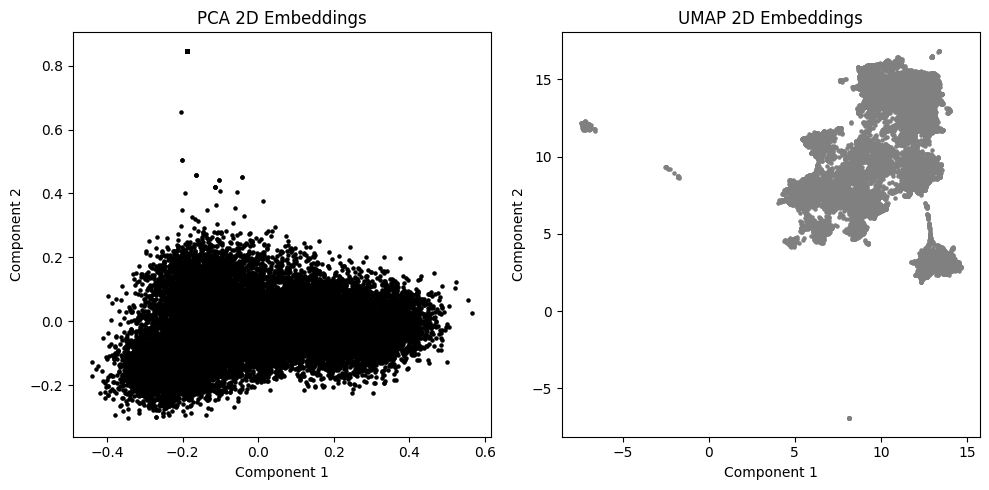

In [6]:
# Plot the 2D visualizations
figure, axs = plt.subplots(1, 2, figsize=(10, 5))

# Plot PCA 2D embeddings
axs[0].scatter(pca_embeddings[:, 0], pca_embeddings[:, 1], s=5, c='black')
axs[0].set_title("PCA 2D Embeddings")
axs[0].set_xlabel("Component 1")
axs[0].set_ylabel("Component 2")

# Plot UMAP 2D embeddings
axs[1].scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], s=5, c='gray')
axs[1].set_title("UMAP 2D Embeddings")
axs[1].set_xlabel("Component 1")
axs[1].set_ylabel("Component 2")

plt.tight_layout()
plt.show()

## **Clustering Documents: KMeans and HDBSCAN**

We will reduce our sentence embeddings to **2 dimensions using UMAP** and cluster the documents into meaningful groups.

### **Why Clustering?**
Clustering helps us discover patterns in the data by grouping similar documents together. Since the **20 Newsgroups dataset** contains documents from **20 different categories**, we will attempt to cluster our documents into **20 clusters**.

### **KMeans: A Simple but Effective Clustering Algorithm**
- KMeans partitions data into **K** clusters by minimizing the distance between points and their cluster center.
- It works well when clusters are **spherical and evenly sized**.
- We will set **K=20** since we know the dataset has 20 categories.

### **HDBSCAN: A Density-Based Approach**
- HDBSCAN (**Hierarchical Density-Based Spatial Clustering of Applications with Noise**) is an improved version of DBSCAN.
- It **does not require you to specify the number of clusters**. Instead, it finds clusters based on density.
- It can **identify outliers** and mark them as noise.
- It works well when clusters have **uneven densities** and **complex shapes**.
- Carefully tune the `min_cluster_size` and `min_samples` parameters to see how they affect the clustering. You can read more about HDBSCAN parameters [here](https://hdbscan.readthedocs.io/en/latest/parameter_selection.html).

### **⚠ Important Note About using UMA embeddings in clustering.**
We are using **UMAP-reduced embeddings** (2D) for clustering. UMAP is a powerful non-linear transformation, but it has an important limitation:
- **UMAP forces separation in the data**, even if the original dataset has no true clusters.
- This means that even if we had completely random embeddings, UMAP might still make them look clusterable.
- Always interpret clustering results with caution!

Now, let’s apply **KMeans** and **HDBSCAN** clustering to our UMAP embeddings.


In [7]:
# Import clustering algorithms
from sklearn.cluster import KMeans
import hdbscan

def apply_kmeans(embeddings, n_clusters=20):
    """
    Apply KMeans clustering to the embeddings.
    
    Parameters:
    - embeddings: The reduced-dimensionality UMAP embeddings (NumPy array).
    - n_clusters: The number of clusters to find (default: 20).
    
    Returns:
    - Cluster labels assigned by KMeans.
    """

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = kmeans.fit_predict(embeddings)
    return labels  # Students should inspect the output

def apply_hdbscan(embeddings, min_cluster_size=10, min_samples=5):
    """
    Apply HDBSCAN clustering to the embeddings.
    
    Parameters:
    - embeddings: The reduced-dimensionality UMAP embeddings (NumPy array).
    - min_cluster_size: The minimum number of samples required to form a cluster (highly important parameter. Adjust to see the effect).
    - min_samples: The number of samples in a neighborhood to consider a point as core (highly important parameter. Adjust to see the effect).
    
    Returns:
    - Cluster labels assigned by HDBSCAN.
    """

    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples)
    labels = clusterer.fit_predict(embeddings)
    return labels  # Students should inspect the output

# Apply clustering
kmeans_start = time()
kmeans_labels = apply_kmeans(umap_embeddings, n_clusters=20)
kmeans_end = time()
print(f"KMeans took {kmeans_end - kmeans_start:.2f} seconds.")
print(f"KMeans found {len(set(kmeans_labels))} clusters (including noise).")

hdbscan_start = time()
hdbscan_labels = apply_hdbscan(umap_embeddings, min_cluster_size=150, min_samples=15)
hdbscan_end = time()
print(f"HDBSCAN took {hdbscan_end - hdbscan_start:.2f} seconds.")
print(f"HDBSCAN found {len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)} clusters (excluding noise).")
num_noise_points = sum(hdbscan_labels == -1)
print(f"HDBSCAN classified {num_noise_points} points as noise.")


KMeans took 1.88 seconds.
KMeans found 20 clusters (including noise).
HDBSCAN took 2.16 seconds.
HDBSCAN found 25 clusters (excluding noise).
HDBSCAN classified 4212 points as noise.


### **Visualizing Clusters: KMeans vs. HDBSCAN**
Now that we have clustered our documents using **KMeans and HDBSCAN**, let's visualize the results in **2D** using PCA.

C:\Users\petra\AppData\Local\Temp\ipykernel_30008\3215014958.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color = plt.cm.get_cmap("tab10")(label % 10)  # Cycle through colors


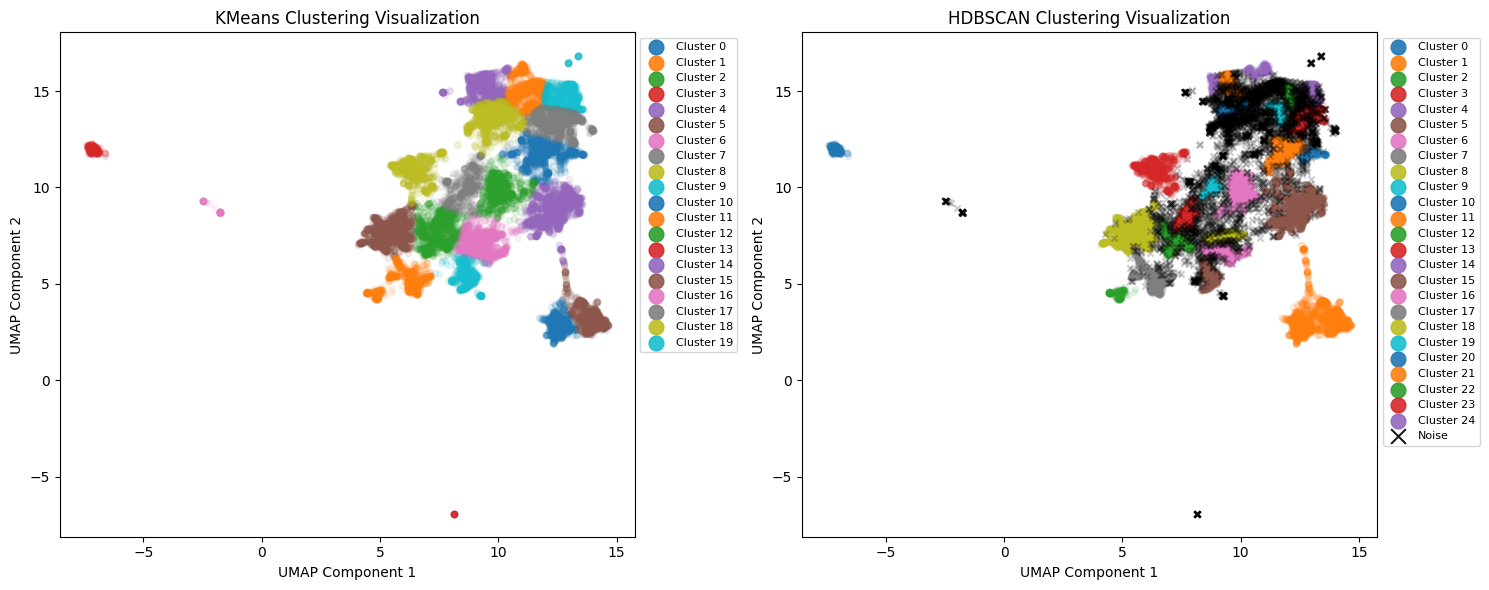

In [8]:
import matplotlib.pyplot as plt
import numpy as np

def plot_clusters(embeddings_2d, labels, title, ax, noise_label=-1):
    """
    Plot 2D visualization of clustered embeddings with different colors and transparency levels.

    Parameters:
    - embeddings_2d: 2D-reduced embeddings from PCA or UMAP.
    - labels: Cluster labels from KMeans or HDBSCAN.
    - title: Title of the plot.
    - ax: Matplotlib axis object to plot on.
    - noise_label: Label representing noise (default: -1 for HDBSCAN).
    """
    unique_labels = set(labels)

    for label in unique_labels:
        if label == noise_label:  # Handle noise points
            color = "black"
            label_name = "Noise"
            alpha = 0.2
            marker = 'x'  # Differentiate noise points
        else:
            color = plt.cm.get_cmap("tab10")(label % 10)  # Cycle through colors
            label_name = f"Cluster {label}"
            alpha = 0.1
            marker = 'o'  # Keep cluster markers as circles
        
        ax.scatter(
            embeddings_2d[labels == label, 0], embeddings_2d[labels == label, 1],
            alpha=alpha, s=20, c=[color], marker=marker,
        )

        # Add legend markers with high alpha (0.9) for better visibility
        ax.scatter([], [], color=color, alpha=0.9, label=label_name, marker=marker, s=50)

    ax.set_xlabel("UMAP Component 1")
    ax.set_ylabel("UMAP Component 2")
    ax.set_title(title)
    ax.legend(markerscale=1.5, bbox_to_anchor=(1, 1), loc="upper left", fontsize=8)

# Convert labels to NumPy arrays for easier indexing
kmeans_labels = np.array(kmeans_labels)
hdbscan_labels = np.array(hdbscan_labels)

# Create a figure with two subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Plot KMeans Clusters
plot_clusters(umap_embeddings, kmeans_labels, "KMeans Clustering Visualization", axs[0])

# Plot HDBSCAN Clusters (includes noise points)
plot_clusters(umap_embeddings, hdbscan_labels, "HDBSCAN Clustering Visualization", axs[1])

plt.tight_layout()
plt.show()


## **Interpreting Clusters with Class-Based TF-IDF**
Once we have clustered the documents, we need to **understand what each cluster represents**. One way to achieve this is by extracting **important keywords** from each cluster.

### **What is Class-Based TF-IDF?**
Term Frequency-Inverse Document Frequency (**TF-IDF**) is a method used to determine the importance of words in a document within a corpus. Class-Based TF-IDF extends this idea to clusters:
- Instead of calculating TF-IDF per document, it is calculated **per cluster**.
- Words that are **uniquely important in a specific cluster** get a higher score.
- This helps us identify the **most representative words** for each topic.

### **How It Works:**
1. **Tokenize and preprocess the documents** (removing stopwords, lowercasing, etc.).
2. **Combine all documents in a cluster** into a single document.
3. **Compute the TF-IDF scores** for terms in the cluster documents.
4. **Extract the top keywords** based on their TF-IDF scores to represent each cluster.


### **Why Use Class-Based TF-IDF?**
- It helps us **interpret** the meaning behind each cluster.
- It highlights **distinctive words** for each topic.
- It allows us to **label** topics based on their most relevant words.

Now, let’s implement this using our clustered documents.


In [9]:
def compute_class_tfidf(documents, labels, top_n=10):
    """
    Compute class-based TF-IDF to extract representative keywords for each cluster.
    
    Parameters:
    - documents: List of text documents.
    - labels: Cluster labels for each document.
    - top_n: Number of top keywords to extract per cluster.
    
    Returns:
    - Dictionary mapping each cluster label to its top keywords.
    - Dictionary mapping each cluster label to the list of associated documents.
    - Dictionary mapping each cluster to the number of documents.
    """
    cluster_texts = defaultdict(list)
    cluster_doc_samples = defaultdict(list)

    # Group documents by their cluster label
    for idx, (doc, label) in enumerate(zip(documents, labels)):
        if label != -1:  # Ignore noise points (for HDBSCAN)
            cluster_texts[label].append(doc)
            cluster_doc_samples[label].append((idx, doc))  # Store index and document

    # Convert each cluster's documents into a single "document"
    cluster_corpus = {label: " ".join(texts) for label, texts in cluster_texts.items()}
    cluster_labels = list(cluster_corpus.keys())

    # Apply TF-IDF vectorization
    vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
    tfidf_matrix = vectorizer.fit_transform(cluster_corpus.values())
    feature_names = vectorizer.get_feature_names_out()

    # Get top N words for each cluster
    cluster_keywords = {}
    for idx, label in enumerate(cluster_labels):
        tfidf_scores = tfidf_matrix[idx].toarray().flatten()
        top_indices = tfidf_scores.argsort()[-top_n:][::-1]  # Get indices of top N words
        top_words = [feature_names[i] for i in top_indices]
        cluster_keywords[label] = top_words

    # Get cluster sizes
    cluster_sizes = {label: len(texts) for label, texts in cluster_texts.items()}
    
    return cluster_keywords, cluster_doc_samples, cluster_sizes

# Apply Class-Based TF-IDF for each clustering method
kmeans_keywords, kmeans_doc_samples, kmeans_cluster_sizes = compute_class_tfidf(documents, kmeans_labels, top_n=10)
hdbscan_keywords, hdbscan_doc_samples, hdbscan_cluster_sizes = compute_class_tfidf(documents, hdbscan_labels, top_n=10)


In [10]:
def print_top_clusters(cluster_keywords, cluster_doc_samples, cluster_sizes, clustering_name, top_n_clusters=5):
    """
    Prints the largest clusters with their number of documents, top keywords, and sample documents.

    Parameters:
    - cluster_keywords: Dictionary of cluster -> top keywords.
    - cluster_doc_samples: Dictionary of cluster -> sample documents.
    - cluster_sizes: Dictionary of cluster -> number of documents.
    - clustering_name: Name of the clustering method (e.g., "KMeans" or "HDBSCAN").
    - top_n_clusters: Number of largest clusters to print.
    """
    print(f"\n=== {clustering_name} - Top {top_n_clusters} Largest Clusters ===")
    
    # Sort clusters by size (largest first)
    sorted_clusters = sorted(cluster_sizes.items(), key=lambda x: x[1], reverse=True)[:top_n_clusters]

    for cluster, size in sorted_clusters:
        print(f"\nCluster {cluster} - {size} documents")
        print(f"Top Keywords: {', '.join(cluster_keywords[cluster])}")

# Example usage
print_top_clusters(kmeans_keywords, kmeans_doc_samples, kmeans_cluster_sizes, "KMeans", top_n_clusters=5)
print_top_clusters(hdbscan_keywords, hdbscan_doc_samples, hdbscan_cluster_sizes, "HDBSCAN", top_n_clusters=5)


=== KMeans - Top 5 Largest Clusters ===

Cluster 4 - 1742 documents
Top Keywords: car, bike, like, just, don, know, cars, new, good, engine

Cluster 5 - 1595 documents
Top Keywords: god, jesus, people, christ, bible, christians, church, does, don, believe

Cluster 6 - 1321 documents
Top Keywords: people, gun, don, think, stephanopoulos, batf, fbi, president, know, just

Cluster 17 - 1225 documents
Top Keywords: monitor, mhz, like, card, mac, use, vga, cpu, drive, know

Cluster 18 - 1146 documents
Top Keywords: jpeg, image, file, edu, graphics, ftp, program, available, use, files

=== HDBSCAN - Top 5 Largest Clusters ===

Cluster 1 - 1898 documents
Top Keywords: game, team, hockey, season, nhl, year, games, pit, players, 10

Cluster 5 - 1757 documents
Top Keywords: bike, car, like, just, don, bmw, bikes, engine, cars, know

Cluster 8 - 1549 documents
Top Keywords: god, jesus, christ, bible, christians, people, church, christian, does, don

Cluster 3 - 974 documents
Top Keywords: vitami

## **Final Remarks: Reflecting on the Pipeline**

You have now successfully implemented a **topic modeling pipeline**, applying **sentence transformers, dimensionality reduction, clustering, and class-based TF-IDF** to extract insights from text data. However, as with any machine learning approach, it is essential to think critically about the results and potential limitations.

### **🧐 What Do You Think About This Technique?**
- Did the clustering results align with your expectations?
- Were the extracted keywords truly representative of each topic?
- How would you explain the advantages and drawbacks of this approach to someone unfamiliar with topic modeling?

### **⚠ What Are the Typical Challenges in This Procedure?**
- **Validation:** How can we **measure** the quality of the discovered topics?
- **Robustness:** Would the results change significantly if we altered **hyperparameters**, used **a different transformer model**, or applied **a different clustering algorithm**?
- **Topic Drift:** If we applied this method to real-world streaming data (e.g., news articles over time), how would we handle **evolving topics**?
- **Bias in Representation:** Do certain clusters receive higher importance due to the dataset’s structure rather than actual topic separability?

### **🔍 Exploring Other Topic Modeling Techniques**
The method we implemented follows a **dense embedding + clustering** approach. However, other approaches exist, each with different strengths and weaknesses:
- **Latent Dirichlet Allocation (LDA):** A probabilistic generative model that assigns words to topics based on co-occurrence.
- **Non-Negative Matrix Factorization (NMF):** A matrix decomposition technique that discovers hidden topics in text.
- **BERTopic with Dynamic Topics:** An extension of BERTopic that allows **topics to evolve over time**, useful for monitoring trends.
- **Graph-Based Approaches:** Topic modeling techniques based on **community detection in word co-occurrence networks**.

### **🚀 Where Do We Go From Here?**
If you're interested in exploring further, consider:
- Comparing **different embedding models** to see how they affect clustering.
- Trying **different clustering techniques** beyond KMeans and HDBSCAN.
- Investigating **unsupervised topic evaluation metrics** to quantify topic coherence.
- Exploring **hybrid models** that combine deep learning with probabilistic modeling for better topic discovery.
